In [1]:
#Imports

#custom
import cvp
from importlib import reload
reload(cvp)

#plotting
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import arcadia_pycolor as apc
apc.mpl.setup()
apc.plotly.setup()
#apc.mpl.style_plot(ax, monospaced_axes="y")
#apc.mpl.set_xaxis_categorical()

#matrices
import numpy as np
import pandas as pd

#segmentation
import cellpose
import skimage as ski
from arcadia_microscopy_tools import Channel
from arcadia_microscopy_tools.batch import ImageBatch
from arcadia_microscopy_tools.model import SegmentationModel
from arcadia_microscopy_tools.operations import (
    get_background_subtracted_intensities,
    rescale_intensity_by_percentiles,
)
from arcadia_microscopy_tools.pipeline import ImageOperation, Pipeline
from natsort import natsorted

#basic tools
import random
import time
import math
import copy
import itertools
from importlib import reload 

#file management and reading
import json
import zarr
import os, psutil
import gc
from dataclasses import is_dataclass, asdict
from datetime import date, datetime
from enum import Enum
import pickle
from pathlib import Path
import sys
sys.path.append("..")

#stats
from scipy import stats
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage
from scipy.stats import gaussian_kde
from scipy import linalg as LA
from scipy.stats import zscore
from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import cosine
from scipy.cluster.hierarchy import leaves_list
from statsmodels.graphics.gofplots import qqplot_2samples
from statsmodels.graphics.gofplots import ProbPlot

#ml
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.manifold import TSNE

apc.mpl.setup()
#apc.plotly.setup()

In [2]:
n_wells=2
n_ims_per_well_2_analyze=1
cell_count_cutoff=50


#Early Stationary Phase Chlorella UV Mutants

#CHLORELLA Example
fig_prefix_20260306_113010_549_1='20260306_113010_549'
fig_prefix_20260306_113010_549_2='20260306_113010_549'
fig_prefix_20260306_113010_549_3='20260306_113010_549'


# fig_prefix_20260111_165957_639,
fig_prefices=[fig_prefix_20260306_113010_549_1,
              fig_prefix_20260306_113010_549_2,
              fig_prefix_20260306_113010_549_3]


col_titles = ["example_dup_1",
              "example_dup_2", 
              "example_dup_3"]

#color scheme for experimental conditions
ytick_colors=[apc.vital, apc.wish, apc.dress]


In [3]:
# THIS IS WHERE THE ANALYSIS BEGINS!

In [4]:
# Load Data (this cell will take a couple of minutes)

# Zroots is where the data is read from
zroots=[]
zpaths=[]
# prebuild JSONL Path/Indices to make reading data faster
jsonl_paths=[]
jsonly_idces=[]

for fp in fig_prefices:
    ZARR_PATH ='experiment_batches_'+fp+'_features.zarr'
    JSONL_PATH='experiment_batches_'+fp+'_features.jsonl'

    zroots.append(cvp.ExperimentStore(ZARR_PATH,JSONL_PATH))
    zpaths.append(ZARR_PATH)
    
    jsonl_paths.append(JSONL_PATH)
    #prebulding these indices allows for faster recall of the data
    jsonly_idces.append(cvp.build_jsonl_offset_index(JSONL_PATH))

#auto check for the empty wells
experiments_to_check=[0]
dead_wells=[]
for e in experiments_to_check:
    for well in range(2):
        if len(zroots[e].get_cell_properties(0, well, "BF")) < cell_count_cutoff: #only using one field of view (0) for autochecking
            if well not in dead_wells:
                dead_wells.append(well)

dead_wells.sort()
dead_ids=[]
for b in range(n_ims_per_well_2_analyze):
    for d in dead_wells:
        dead_ids.append(d+(b*n_wells))


# these are the features that are automatically exctracted from arcadia's microscopy tools
cellpose_features=zroots[e].get_cell_properties(0, well, "BF").columns.tolist()
cellpose_features[0]='count'

In [5]:
zroots[0].get_raw_intensities(0, 0, "BF")

array([[7923, 8058, 8034, ..., 7894, 8047, 7866],
       [8154, 8293, 8156, ..., 7829, 7763, 7614],
       [8368, 8114, 8234, ..., 8433, 7948, 7763],
       ...,
       [8384, 8395, 8393, ..., 8155, 8108, 8059],
       [8346, 8177, 8607, ..., 7912, 8393, 7816],
       [7474, 7783, 8278, ..., 7033, 6891, 7011]],
      shape=(1024, 1024), dtype=uint16)

In [6]:
zroots[0].get_processed_intensities(0, 0, "BF")

array([[0.7502658 , 0.7789021 , 0.7957441 , ..., 0.7783072 , 0.79244274,
        0.7585812 ],
       [0.8097187 , 0.8221186 , 0.8154832 , ..., 0.7887115 , 0.7497858 ,
        0.707256  ],
       [0.8439234 , 0.8138716 , 0.82358783, ..., 0.8682775 , 0.79226625,
        0.7404787 ],
       ...,
       [0.90920264, 0.90004265, 0.9200117 , ..., 0.95520955, 0.96624327,
        0.94112456],
       [0.8597864 , 0.8661051 , 0.9361461 , ..., 0.89429605, 0.9247907 ,
        0.8555408 ],
       [0.6796217 , 0.75835353, 0.854514  , ..., 0.6495437 , 0.6458756 ,
        0.6444252 ]], shape=(1024, 1024), dtype=float32)

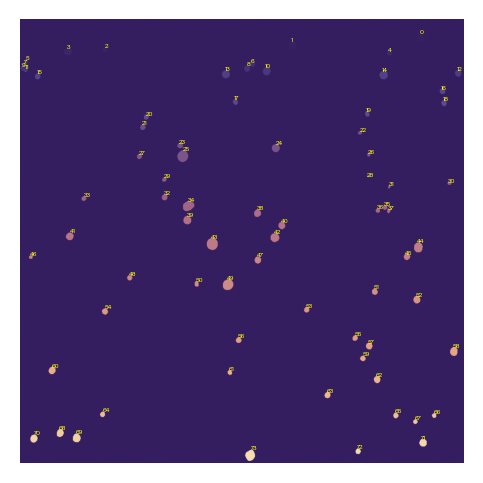

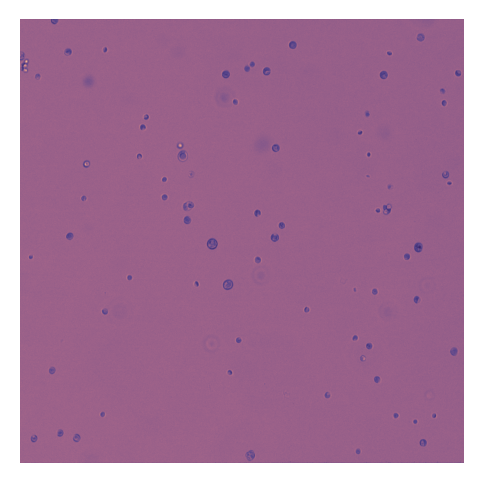

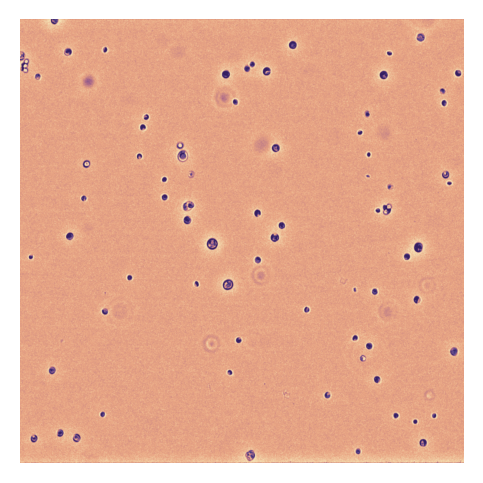

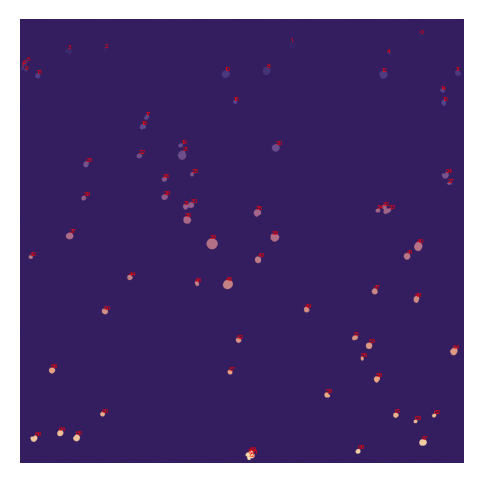

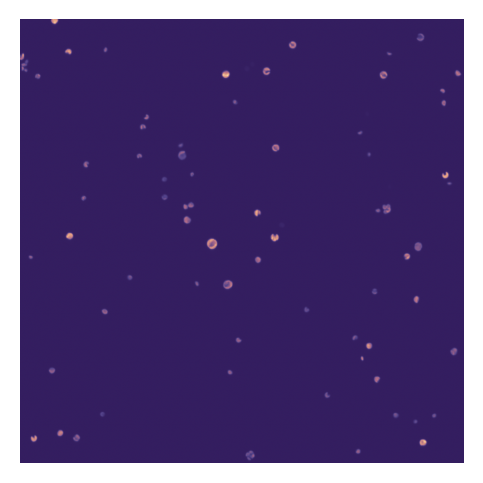

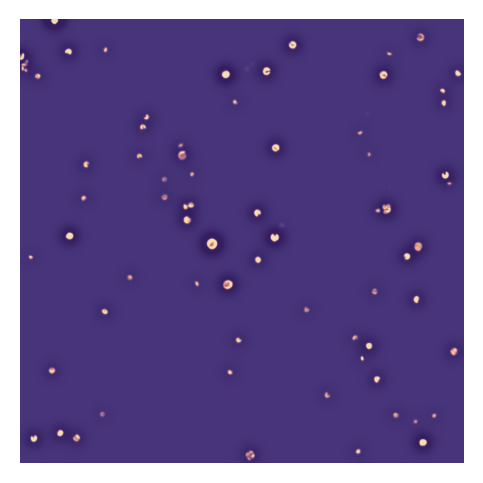

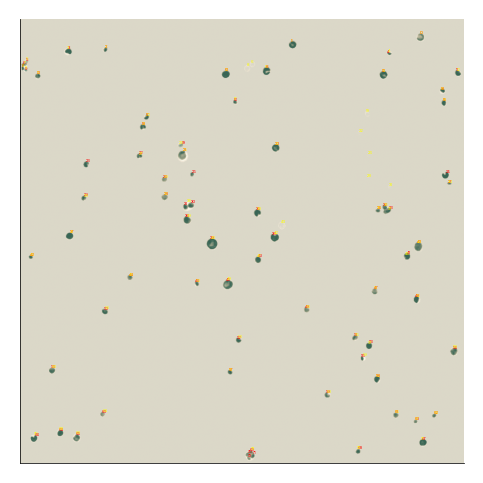

In [7]:
cvp.showcase_clone_images_1_by_1(zroots,
                             experiment=0,
                             field_of_view=0,
                             well=0,
                             f_size=[8, 8],
                             f_size_2=[8, 8],
                             show_labels=True,
                             marker_size_1=6,
                             marker_size_2=4,
                             marker_color_bf='yellow',
                             marker_color_cy='red')